# Midterm data processing

CP101 Track B, Group 11. Run with Restart & Run All. The raw data comes from `analysis/data_download.py` (see README)

We run the same analysis three times with 250 m, 500 m and 1,000 m walking circles around each BART station. All data is projected to EPSG:26910 (meters)

In [ ]:
import sys
sys.path.append('..')  # so python can find the analysis folder

import pandas as pd
from analysis import pipeline as p

## 1. Load, clean data
Each step prints the row counts before and after.

In [ ]:
stations = p.load_stations()
tracts = p.load_tracts()
jobs = p.load_jobs()
tracts_jobs = p.add_jobs_to_tracts(tracts, jobs)

stations - keep parent stations : 287 -> 50 (platform rows would count each station more than once)
stations - drop missing coordinates : 50 -> 50 (cannot map a station without a location)
tracts - keep the 5 counties : 9129 -> 1447 (only the BART counties are in our study area)
tracts - drop tracts with no land : 1447 -> 1442 (water-only tracts have no jobs)
jobs - keep blocks in the 5 counties : 262357 -> 39265 (LODES covers all of California)
jobs - add up blocks to tracts : 39265 -> 1441 (we join to tracts, not blocks)
tracts - set jobs to 0 for 1 tracts not in LODES : 1442 -> 1442 (LODES only lists blocks that have jobs)


## 2. Spatial joins
First each station is joined to the tract it is in (to get its county). Then each walking circle is joined to the tracts it touches, and each tract's jobs are split by how much of the tract is inside the circle.

In [ ]:
stations = p.add_county(stations, tracts_jobs)

results = {}
for meters in [250, 500, 1000]:
    results[meters] = p.run_radius(stations, tracts_jobs, meters)

all_results = pd.concat(list(results.values()))
all_results.groupby('radius')[['jobs_total', 'lowwage_pct']].mean()

stations - spatial join to tracts : 50 -> 50 (stations outside the 5 counties would be dropped)
catchments - 250 m join : 50 -> 50 (stations whose circle touches at least one tract)
catchments - 500 m join : 50 -> 50 (stations whose circle touches at least one tract)
catchments - 1000 m join : 50 -> 50 (stations whose circle touches at least one tract)


,jobs_total,lowwage_pct
radius,,
250,2498.727117,14.654412
500,9641.122677,14.275675
1000,26792.513623,13.768300


In [ ]:
results[500].sort_values('jobs_total', ascending=False).head(10)

,stop_id,stop_name,geometry,county,jobs_total,jobs_low,lowwage_pct,radius
5,MONT,Montgomery Street,POINT (552689.358 4182592.351),San Francisco,130505.180506,6504.862943,4.984371,500
4,EMBR,Embarcadero,POINT (553087.415 4182993.123),San Francisco,78759.505509,3628.487942,4.607048,500
6,POWL,Powell Street,POINT (552186.815 4182082.423),San Francisco,58011.131949,5457.455789,9.407601,500
7,CIVC,Civic Center / UN Plaza,POINT (551618.515 4181502.103),San Francisco,48929.766687,3605.057556,7.367821,500
1,19TH,19th Street Oakland,POINT (564368.488 4184773.031),Alameda,35763.007027,2709.516980,7.576312,500
0,12TH,12th Street / Oakland City Center,POINT (564119.647 4184261.127),Alameda,35164.874628,3213.284583,9.137768,500
31,DBRK,Downtown Berkeley,POINT (564371.683 4191656.009),Alameda,12263.675975,2008.503809,16.377665,500
13,LAKE,Lake Merritt,POINT (564686.933 4183582.07),Alameda,11171.058398,848.399721,7.594623,500
8,16TH,16th Street / Mission,POINT (551110.691 4179919.513),San Francisco,7002.314722,992.116178,14.168403,500
26,PHIL,Pleasant Hill / Contra Costa Centre,POINT (582964.632 4198294.812),Contra Costa,5192.461220,422.775858,8.142109,500


In [ ]:
all_results.drop(columns='geometry').to_csv('../data/processed/station_jobs.csv', index=False)
pd.DataFrame(p.cleaning_log).to_csv('../data/processed/cleaning_log.csv', index=False)
pd.DataFrame(p.cleaning_log)

,dataset,step,rows_before,rows_after,reason
0,stations,keep parent stations,287,50,platform rows would count each station more th...
1,stations,drop missing coordinates,50,50,cannot map a station without a location
2,tracts,keep the 5 counties,9129,1447,only the BART counties are in our study area
3,tracts,drop tracts with no land,1447,1442,water-only tracts have no jobs
4,jobs,keep blocks in the 5 counties,262357,39265,LODES covers all of California
5,jobs,add up blocks to tracts,39265,1441,"we join to tracts, not blocks"
6,tracts,set jobs to 0 for 1 tracts not in LODES,1442,1442,LODES only lists blocks that have jobs
7,stations,spatial join to tracts,50,50,stations outside the 5 counties would be dropped
8,catchments,250 m join,50,50,stations whose circle touches at least one tract
9,catchments,500 m join,50,50,stations whose circle touches at least one tract


## 3. Map

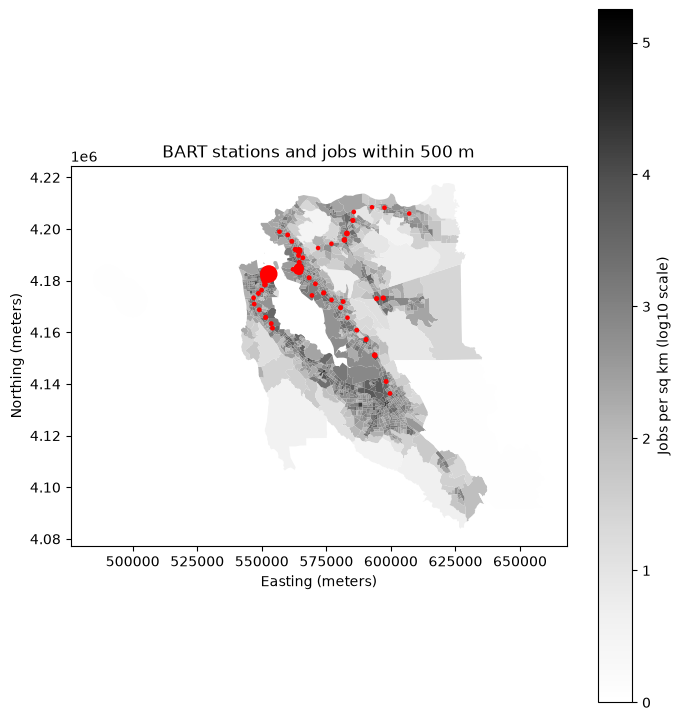

In [ ]:
p.make_map(tracts_jobs, results[500], 500)

## 4. Charts

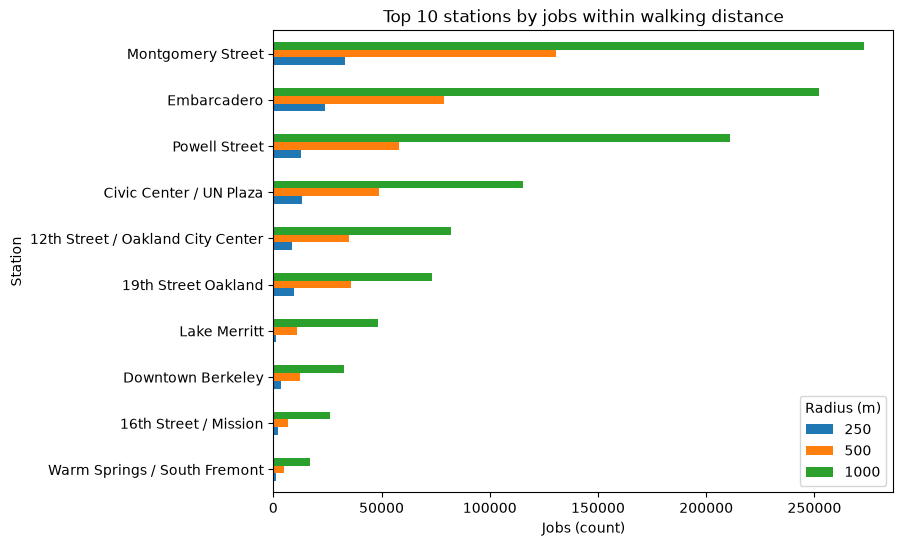

In [ ]:
p.chart_top_stations(all_results)

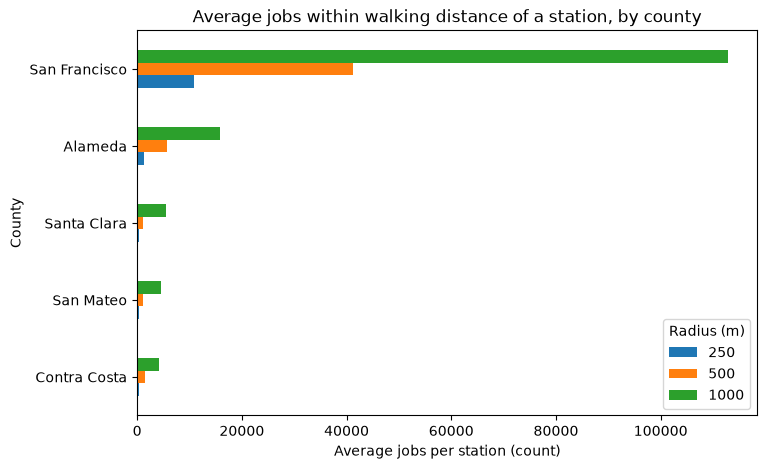

In [ ]:
p.chart_by_county(all_results)

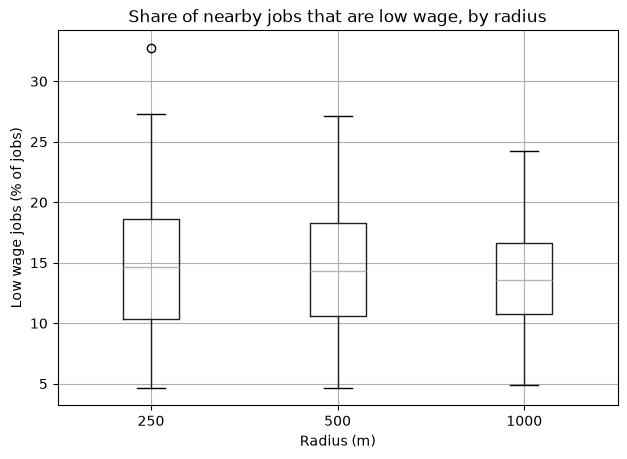

In [ ]:
p.chart_lowwage(all_results)